# 🐱🐶 Perbandingan 7 Arsitektur CNN pada Klasifikasi Cat vs Dog

**Dataset:** Cat or Dog Image Classification (Kaggle, sunilthite)
**Framework:** PyTorch (jalan di Kaggle GPU)

**Arsitektur yang dibandingkan:** LeNet-5 · AlexNet · ZFNet · VGG16 · GoogLeNet · ResNet-18 · Capsule Network

### Kenapa dibandingkan, bukan pilih satu?
Supaya kita bisa melihat **evolusi CNN dari 1998 sampai 2017** dan menjawab pertanyaan:
*apakah arsitektur yang lebih dalam/modern selalu lebih bagus untuk dataset sekecil ini?*

### Prinsip eksperimen yang adil (fair comparison)
Semua model memakai **kondisi yang sama persis**:
- data yang sama (split train / val / test sama)
- ukuran input sama: **128×128 RGB**
- training **from scratch** (tanpa pretrained weights)
- optimizer sama (AdamW + OneCycleLR), jumlah epoch sama, augmentasi sama
- model terbaik dipilih berdasarkan **validation accuracy**, lalu dites **sekali** di test set

### Alur notebook
1. Setup & konfigurasi
2. Load dataset dan split (train / val / test)
3. Preprocessing (resize, normalisasi, augmentasi)
4. Definisi 7 arsitektur (+ penjelasan masing-masing)
5. Training engine
6. Training semua model
7. Evaluasi, visualisasi, dan kesimpulan

## 1. Setup & Konfigurasi

Parameter penting ada di sel di bawah. **Untuk uji coba cepat**, set `QUICK_TEST = True` (pakai sedikit data dan 2 epoch) supaya kamu bisa cek semua sel jalan tanpa error sebelum training penuh.

In [1]:
import os, time, math, random, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# ---------------- KONFIGURASI ----------------
DATA_ROOT  = os.environ.get("DATA_ROOT", "/kaggle/input")      # folder input dataset Kaggle
WORK_DIR   = os.environ.get("WORK_DIR", "/kaggle/working")     # folder output Kaggle
IMG_SIZE   = 128        # semua model memakai input 128x128
BATCH_SIZE = 64
EPOCHS     = int(os.environ.get("EPOCHS", 25))   # 10-15 cukup untuk perbandingan
VAL_RATIO  = 0.15       # 15% dari data train dipakai sebagai validation
SEED       = 42
QUICK_TEST = False      # True = cek cepat (data sedikit, 2 epoch)

MODELS_TO_RUN = ["LeNet-5", "AlexNet", "ZFNet", "VGG16", "GoogLeNet", "ResNet18", "CapsNet"]
# contoh kalau mau subset: MODELS_TO_RUN = ["LeNet-5", "ResNet18"]
# ---------------------------------------------

if QUICK_TEST:
    EPOCHS = 2

os.makedirs(WORK_DIR, exist_ok=True)
CLASS_NAMES = ["cat", "dog"]

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

seed_everything(SEED)
DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"      # mixed precision: lebih cepat & hemat memori di GPU
torch.backends.cudnn.benchmark = True

print("PyTorch:", torch.__version__)
print("Device :", DEVICE, "|", torch.cuda.get_device_name(0) if USE_AMP else "CPU (lambat! aktifkan GPU di Kaggle)")

PyTorch: 2.11.0+cu130
Device : cuda | Tesla T4


## 2. Load Dataset & Split

Kode di bawah **otomatis mencari** semua gambar di `/kaggle/input`, lalu menentukan:
- **label** dari nama folder/file (`cat...` → 0, `dog...` → 1)
- **split** dari nama folder (`train...` atau `test...`)

Jadi tidak masalah kalau struktur foldernya sedikit berbeda. **Cek output tabel jumlah gambar** di bawah dan pastikan angkanya masuk akal (±23 ribu train, ±3.8 ribu test).

**Pembagian data:**
- `train` (85% dari folder train) → untuk belajar
- `val` (15% dari folder train) → untuk memilih epoch/model terbaik
- `test` → dipakai **hanya sekali di akhir** untuk skor final (tidak boleh dipakai untuk tuning, supaya tidak *data leakage*)

In [2]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def label_from_path(p: Path):
    folder, fname = p.parent.name.lower(), p.name.lower()
    for s in (folder, fname):
        if s.startswith("cat"): return 0
        if s.startswith("dog"): return 1
    return None

def split_from_path(p: Path):
    parts = [x.lower() for x in p.parent.parts]
    if any("train" in x for x in parts): return "train"
    if any("test" in x for x in parts):  return "test"
    return None

files = [p for p in Path(DATA_ROOT).rglob("*") if p.suffix.lower() in IMG_EXT]
records = []
for p in files:
    y = label_from_path(p)
    if y is not None:
        records.append((str(p), y, split_from_path(p)))

df = pd.DataFrame(records, columns=["path", "label", "split"])
assert len(df) > 0, "Dataset tidak ketemu! Pastikan sudah Add Input -> dataset Cat or Dog di Kaggle."
print("Total gambar terdeteksi:", len(df))
print(df.groupby(["split", "label"], dropna=False).size().unstack().rename(columns={0: "cat", 1: "dog"}))

# ----- tentukan train/test -----
if {"train", "test"}.issubset(set(df["split"].dropna().unique())):
    train_full = df[df["split"] == "train"].reset_index(drop=True)
    test_df    = df[df["split"] == "test"].reset_index(drop=True)
else:  # fallback: struktur tidak punya train/test -> split sendiri 80/20
    print("⚠️ Folder train/test tidak terdeteksi, melakukan split 80/20 sendiri.")
    train_full, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
    train_full, test_df = train_full.reset_index(drop=True), test_df.reset_index(drop=True)

train_df, val_df = train_test_split(train_full, test_size=VAL_RATIO, stratify=train_full["label"], random_state=SEED)

if QUICK_TEST:
    train_df = train_df.sample(min(1500, len(train_df)), random_state=SEED)
    val_df   = val_df.sample(min(300, len(val_df)), random_state=SEED)
    test_df  = test_df.sample(min(300, len(test_df)), random_state=SEED)

print(f"\nTrain: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Total gambar terdeteksi: 27513
label    cat    dog
split              
test    1944   1919
train  11823  11827

Train: 20102 | Val: 3548 | Test: 3863


## 3. Preprocessing

**Strategi:** semua gambar dibaca **sekali**, di-resize ke 128×128, lalu disimpan sebagai tensor `uint8` **langsung di memori GPU** (±1.3 GB). Efeknya training jadi sangat cepat karena tidak ada bottleneck baca file dari disk / DataLoader CPU di setiap epoch.

**Normalisasi:** nilai piksel dikurangi mean & dibagi std ImageNet (supaya nilai input kira-kira berpusat di 0 dan stabil untuk training).

**Augmentasi (hanya di data train, dilakukan di GPU):**
- *Random horizontal flip* → kucing/anjing dibalik kiri-kanan tetap kucing/anjing
- *Random translation* (geser ±8 piksel dengan reflect padding) → model tidak bergantung pada posisi objek

Augmentasi mengurangi **overfitting**, dan penting karena kita melatih model besar dari nol.

In [3]:
def load_img(path):
    try:
        with Image.open(path) as im:
            im = im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
            return np.asarray(im, dtype=np.uint8)
    except Exception:
        return None   # file rusak -> dilewati

def load_split(frame, name):
    paths, labels = frame["path"].tolist(), frame["label"].tolist()
    with ThreadPoolExecutor(max_workers=os.cpu_count() or 4) as ex:
        arrs = list(tqdm(ex.map(load_img, paths), total=len(paths), desc=f"load {name}"))
    keep = [i for i, a in enumerate(arrs) if a is not None]
    if len(keep) < len(arrs):
        print(f"  {len(arrs) - len(keep)} file rusak dilewati di {name}")
    X = torch.from_numpy(np.stack([arrs[i] for i in keep])).permute(0, 3, 1, 2).contiguous().to(DEVICE)  # (N,3,H,W) uint8
    y = torch.tensor([labels[i] for i in keep], dtype=torch.long, device=DEVICE)
    return X, y

X_train, y_train = load_split(train_df, "train")
X_val,   y_val   = load_split(val_df, "val")
X_test,  y_test  = load_split(test_df, "test")
print("Shape:", tuple(X_train.shape), tuple(X_val.shape), tuple(X_test.shape))

MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1) * 255
STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1) * 255

def prep(xb, train):
    """uint8 batch -> float ternormalisasi (+ augmentasi bila train)"""
    x = xb.float()
    if train:
        flip = torch.rand(x.size(0), device=x.device) < 0.5
        x = torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)
        pad = 8
        x = F.pad(x, (pad,) * 4, mode="reflect")
        i, j = random.randint(0, 2 * pad), random.randint(0, 2 * pad)
        x = x[:, :, i:i + IMG_SIZE, j:j + IMG_SIZE]
    x = (x - MEAN) / STD
    return x.contiguous(memory_format=torch.channels_last)

load train:   0%|          | 0/20102 [00:00<?, ?it/s]

load val:   0%|          | 0/3548 [00:00<?, ?it/s]

load test:   0%|          | 0/3863 [00:00<?, ?it/s]

Shape: (20102, 3, 128, 128) (3548, 3, 128, 128) (3863, 3, 128, 128)


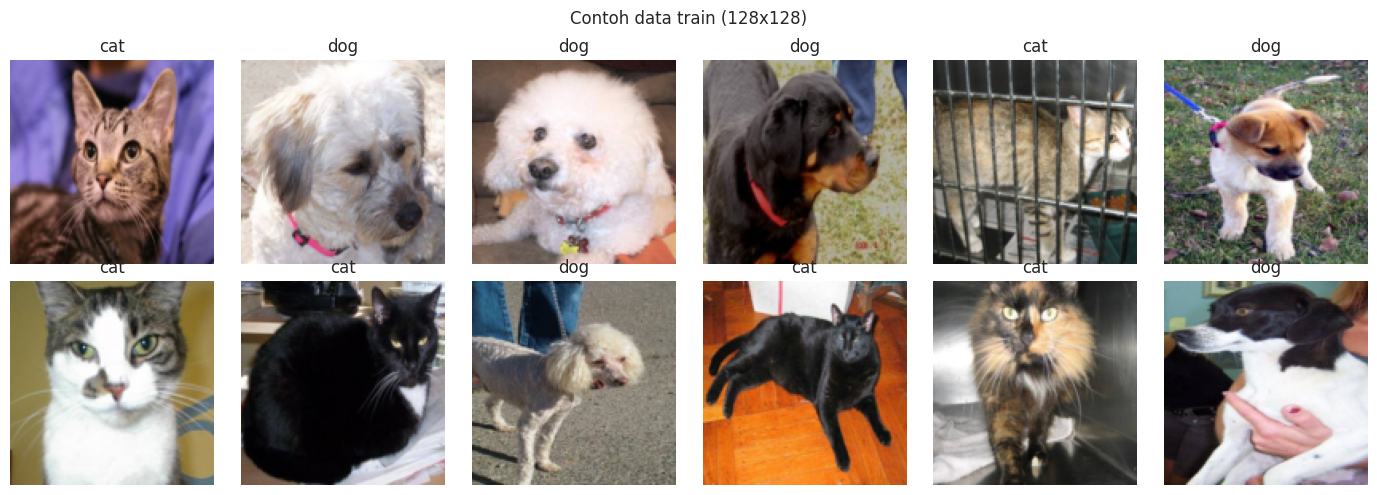

In [4]:
# Lihat contoh data
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
idx = torch.randperm(len(X_train))[:12]
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu().numpy())
    ax.set_title(CLASS_NAMES[y_train[i].item()]); ax.axis("off")
plt.suptitle("Contoh data train (128x128)"); plt.tight_layout(); plt.show()

## 4. Arsitektur Model

Urutan di bawah mengikuti **sejarah perkembangan CNN**. Setiap model punya penjelasan yang bisa langsung dipakai untuk presentasi.

### Tabel ringkas (data dari paper aslinya, bukan dari hasil kita)

| Model | Tahun | Penulis | Kedalaman | Ide kunci |
|---|---|---|---|---|
| LeNet-5 | 1998 | LeCun dkk. | 5 layer berbobot | Konsep dasar: Conv → Pool → FC |
| AlexNet | 2012 | Krizhevsky dkk. | 8 layer | ReLU, Dropout, GPU, augmentasi: awal era deep learning |
| ZFNet | 2013 | Zeiler & Fergus | 8 layer | Visualisasi filter → kernel & stride awal diperkecil |
| VGG16 | 2014 | Simonyan & Zisserman | 16 layer | Hanya kernel 3×3, ditumpuk dalam |
| GoogLeNet | 2014 | Szegedy dkk. | 22 layer | Inception module (multi-skala paralel), 1×1 conv |
| ResNet | 2015 | He dkk. | 18–152 layer | Skip/residual connection |
| CapsNet | 2017 | Sabour, Hinton dkk. | 3 layer | Capsule (vektor) + dynamic routing |

> **Catatan modifikasi:** semua model asli dirancang untuk input 224×224 (LeNet: 32×32) dan ImageNet 1000 kelas. Di sini input 128×128 dan 2 kelas. Ukuran layer fully-connected pertama dihitung otomatis (`LazyLinear`). Beberapa model diberi **BatchNorm** karena melatih dari nol tanpa BatchNorm sangat sulit/lambat konvergen (dijelaskan per model).

### 4.1 LeNet-5 (1998)

**Sejarah:** Yann LeCun, untuk mengenali angka tulisan tangan (MNIST / cek bank). CNN pertama yang praktis dan menjadi fondasi semua CNN setelahnya.

**Ide utama:** pola *Convolution → Pooling → Convolution → Pooling → Fully Connected*. Conv mengekstrak fitur lokal (garis, tepi), pooling mengecilkan ukuran peta fitur, FC mengklasifikasi.

**Arsitektur (di praktikum ini, input 128×128×3):**

| Layer | Detail | Output |
|---|---|---|
| Conv1 | 6 filter 5×5 + Tanh | 124×124×6 |
| AvgPool | 2×2 | 62×62×6 |
| Conv2 | 16 filter 5×5 + Tanh | 58×58×16 |
| AvgPool | 2×2 | 29×29×16 |
| FC1 | 13.456 → 120 + Tanh | 120 |
| FC2 | 120 → 84 + Tanh | 84 |
| FC3 | 84 → 2 | 2 |

**Kelebihan:** sangat kecil dan cepat (±1.6 juta parameter di sini; ±60 ribu pada versi asli), mudah dijelaskan.
**Kekurangan:** hanya 2 layer konvolusi → fitur yang dipelajari sangat sederhana; tidak cukup kuat untuk gambar natural yang kompleks (kucing/anjing dengan berbagai pose, latar, pencahayaan). Aktivasi Tanh + average pooling (gaya lama) membuat gradien mudah mengecil.

**Modifikasi:** input diganti 3 kanal (RGB) dan 128×128; kita pertahankan Tanh dan AvgPool agar tetap setia dengan aslinya.

**Peran dalam eksperimen:** *baseline*. Kalau model modern mengalahkan LeNet-5 jauh, itu menunjukkan nilai kedalaman dan inovasi arsitektur.

In [5]:
class LeNet5(nn.Module):
    def __init__(self, n_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 6, 5), nn.Tanh(), nn.AvgPool2d(2, 2),
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.LazyLinear(120), nn.Tanh(),       # LazyLinear: ukuran input dihitung otomatis
            nn.Linear(120, 84), nn.Tanh(),
            nn.Linear(84, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

### 4.2 AlexNet (2012)

**Sejarah:** Alex Krizhevsky, Sutskever, Hinton. Menang ILSVRC 2012 dengan selisih sangat besar (top-5 error ±15.3% vs ±26% peringkat kedua). Momen "big bang" deep learning.

**Inovasi utama:**
1. **ReLU** menggantikan Tanh/Sigmoid → training jauh lebih cepat, gradien tidak cepat hilang
2. **Dropout (0.5)** di layer FC → mengurangi overfitting
3. **Data augmentation** (flip, crop, dll)
4. **Training di GPU**
5. *Overlapping max pooling* (kernel 3, stride 2)
6. Local Response Normalization (LRN), sekarang sudah jarang dipakai

**Arsitektur (input 128×128×3):** 5 conv + 3 FC

| Layer | Detail | Output |
|---|---|---|
| Conv1 | 96 filter 11×11, stride 4 + BN + ReLU | 31×31×96 |
| MaxPool | 3×3, stride 2 | 15×15×96 |
| Conv2 | 256 filter 5×5 + BN + ReLU | 15×15×256 |
| MaxPool | 3×3, stride 2 | 7×7×256 |
| Conv3 | 384 filter 3×3 + BN + ReLU | 7×7×384 |
| Conv4 | 384 filter 3×3 + BN + ReLU | 7×7×384 |
| Conv5 | 256 filter 3×3 + BN + ReLU | 7×7×256 |
| MaxPool | 3×3, stride 2 | 3×3×256 |
| FC1 | 2304 → 4096 + ReLU + Dropout | 4096 |
| FC2 | 4096 → 4096 + ReLU + Dropout | 4096 |
| FC3 | 4096 → 2 | 2 |

**Kelebihan:** jauh lebih ekspresif daripada LeNet; membuktikan CNN dalam + GPU bisa bekerja pada gambar nyata.
**Kekurangan:** filter 11×11 stride 4 di awal terlalu agresif (membuang detail halus); parameter FC sangat banyak → rawan overfitting.

**Modifikasi:** **BatchNorm menggantikan LRN** (LRN sudah usang, BN lebih stabil & mempercepat konvergensi saat training dari nol).

In [6]:
class AlexNet(nn.Module):
    def __init__(self, n_classes=2):
        super().__init__()
        def block(cin, cout, k, s=1, p=0):
            return [nn.Conv2d(cin, cout, k, s, p, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]
        self.features = nn.Sequential(
            *block(3, 96, 11, 4, 2),  nn.MaxPool2d(3, 2),
            *block(96, 256, 5, 1, 2), nn.MaxPool2d(3, 2),
            *block(256, 384, 3, 1, 1),
            *block(384, 384, 3, 1, 1),
            *block(384, 256, 3, 1, 1), nn.MaxPool2d(3, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5), nn.LazyLinear(4096), nn.ReLU(inplace=True),
            nn.Dropout(0.5), nn.Linear(4096, 4096), nn.ReLU(inplace=True),
            nn.Linear(4096, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

### 4.3 ZFNet (2013)

**Sejarah:** Matthew Zeiler & Rob Fergus. Bukan arsitektur baru dari nol, tapi **perbaikan AlexNet berdasarkan visualisasi**.

**Ide utama:** mereka memakai teknik *deconvnet* untuk **memvisualisasikan apa yang dipelajari tiap layer**. Temuannya: filter 11×11 stride 4 milik AlexNet di layer 1 menghasilkan fitur yang "aliasing" dan banyak filter yang mati/tidak informatif. Solusinya:
- Layer 1: 11×11 stride 4 → **7×7 stride 2** (detail halus lebih terjaga)
- Layer 2: stride diperkecil (5×5 stride 2)
- Layer 3-5 tetap 3×3 (384, 384, 256 filter)

**Arsitektur (input 128×128×3):**

| Layer | Detail | Output |
|---|---|---|
| Conv1 | 96 filter 7×7, stride 2 + BN + ReLU | 62×62×96 |
| MaxPool | 3×3, stride 2 | 30×30×96 |
| Conv2 | 256 filter 5×5, stride 2 + BN + ReLU | 13×13×256 |
| MaxPool | 3×3, stride 2 | 6×6×256 |
| Conv3-5 | 384, 384, 256 filter 3×3 | 6×6×256 |
| MaxPool | 3×3, stride 2 | 2×2×256 |
| FC1, FC2 | 1024 → 4096 → 4096 + Dropout | 4096 |
| FC3 | 4096 → 2 | 2 |

**Kelebihan:** memperbaiki akurasi AlexNet dengan perubahan sederhana; memperkenalkan *visualisasi CNN* sebagai alat debugging.
**Kekurangan:** tetap memakai FC raksasa (rawan overfitting); lebih mahal dihitung daripada AlexNet karena peta fitur awal lebih besar.

**Modifikasi:** BatchNorm ditambahkan seperti pada AlexNet.

**Poin presentasi:** perbedaan AlexNet vs ZFNet adalah **studi kasus bagus** bahwa *memahami* model (lewat visualisasi) bisa mengarah pada perbaikan desain.

In [7]:
class ZFNet(nn.Module):
    def __init__(self, n_classes=2):
        super().__init__()
        def block(cin, cout, k, s=1, p=0):
            return [nn.Conv2d(cin, cout, k, s, p, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]
        self.features = nn.Sequential(
            *block(3, 96, 7, 2, 1),   nn.MaxPool2d(3, 2),
            *block(96, 256, 5, 2, 0), nn.MaxPool2d(3, 2),
            *block(256, 384, 3, 1, 1),
            *block(384, 384, 3, 1, 1),
            *block(384, 256, 3, 1, 1), nn.MaxPool2d(3, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5), nn.LazyLinear(4096), nn.ReLU(inplace=True),
            nn.Dropout(0.5), nn.Linear(4096, 4096), nn.ReLU(inplace=True),
            nn.Linear(4096, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

### 4.4 VGG16 (2014)

**Sejarah:** Visual Geometry Group, Oxford (Simonyan & Zisserman). Peringkat 2 klasifikasi ILSVRC 2014.

**Ide utama:** *gunakan hanya kernel 3×3 dan susun sedalam mungkin.* Dua conv 3×3 berurutan punya *receptive field* sama dengan satu conv 5×5, tiga conv 3×3 setara 7×7, tetapi:
- parameter lebih sedikit (3·(3²C²) = 27C² vs 49C²)
- lebih banyak non-linearitas (ReLU) → fitur lebih diskriminatif

**Arsitektur:** 13 conv + 3 FC = 16 layer berbobot, dibagi 5 blok. Setiap blok diakhiri max-pool 2×2 yang **membagi dua ukuran**, sementara jumlah filter **digandakan** (64 → 128 → 256 → 512 → 512).

| Blok | Isi | Output (input 128) |
|---|---|---|
| 1 | 2× conv3-64 + pool | 64×64×64 |
| 2 | 2× conv3-128 + pool | 32×32×128 |
| 3 | 3× conv3-256 + pool | 16×16×256 |
| 4 | 3× conv3-512 + pool | 8×8×512 |
| 5 | 3× conv3-512 + pool | 4×4×512 |
| FC | 8192 → 4096 → 4096 → 2 (+ Dropout) | 2 |

**Kelebihan:** desain sangat seragam dan elegan (mudah dijelaskan); fitur yang dihasilkan bagus dan sering dipakai untuk *transfer learning*.
**Kekurangan:** **sangat berat**: parameter ±138 juta pada versi asli (sebagian besar di FC), lambat, memori besar. Tanpa BatchNorm, melatih VGG dari nol hampir tidak mungkin konvergen.

**Modifikasi:** versi **VGG16-BN** (BatchNorm setelah tiap conv) supaya bisa dilatih dari nol dalam beberapa epoch.

In [8]:
class VGG16(nn.Module):
    CFG = [64, 64, "M", 128, 128, "M", 256, 256, 256, "M", 512, 512, 512, "M", 512, 512, 512, "M"]
    def __init__(self, n_classes=2):
        super().__init__()
        layers, cin = [], 3
        for v in self.CFG:
            if v == "M":
                layers.append(nn.MaxPool2d(2, 2))
            else:
                layers += [nn.Conv2d(cin, v, 3, padding=1, bias=False), nn.BatchNorm2d(v), nn.ReLU(inplace=True)]
                cin = v
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.LazyLinear(4096), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(4096, 4096), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(4096, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

### 4.5 GoogLeNet / Inception v1 (2014)

**Sejarah:** Google (Szegedy dkk.). **Juara ILSVRC 2014** (top-5 error ±6.7%) dengan parameter hanya ±7 juta, ±20× lebih sedikit dari VGG.

**Pertanyaan yang dijawab:** *berapa ukuran kernel yang paling pas, 1×1, 3×3, atau 5×5?* Jawabannya: **pakai semuanya sekaligus, secara paralel**, lalu gabungkan (concatenate). Ini disebut **Inception module**.

**Isi Inception module (4 cabang paralel):**
1. conv 1×1
2. conv 1×1 (reduksi) → conv 3×3
3. conv 1×1 (reduksi) → conv 5×5
4. max-pool 3×3 → conv 1×1

Hasil keempatnya digabung di sumbu channel.

**Trik penting: conv 1×1 sebagai "bottleneck".** Sebelum conv 3×3 / 5×5 yang mahal, jumlah channel dikurangi dulu dengan conv 1×1 → komputasi turun drastis.

**Fitur lain:**
- **Global Average Pooling** menggantikan FC raksasa → parameter sangat hemat dan mengurangi overfitting
- Versi asli punya **2 auxiliary classifier** (cabang klasifikasi tambahan di tengah jaringan) untuk membantu aliran gradien. *Di praktikum ini tidak dipakai karena BatchNorm sudah membuat training stabil.*

**Arsitektur:** stem (conv 7×7 → pool → conv 1×1 → conv 3×3 → pool) → 9 Inception module (3a, 3b, 4a–4e, 5a, 5b) dengan max-pool di antaranya → GAP → Dropout → FC.

**Kelebihan:** akurat dengan parameter sedikit; menangkap objek berbagai ukuran sekaligus (multi-scale).
**Kekurangan:** desain rumit (banyak hyperparameter manual per module), lebih lambat per parameter karena banyak cabang.

**Modifikasi:** BatchNorm di setiap conv, tanpa auxiliary classifier.

In [9]:
def conv_bn_relu(cin, cout, k, s=1, p=0):
    return nn.Sequential(nn.Conv2d(cin, cout, k, s, p, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class Inception(nn.Module):
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = conv_bn_relu(cin, c1, 1)                                                        # cabang 1x1
        self.b2 = nn.Sequential(conv_bn_relu(cin, c3r, 1), conv_bn_relu(c3r, c3, 3, 1, 1))        # 1x1 -> 3x3
        self.b3 = nn.Sequential(conv_bn_relu(cin, c5r, 1), conv_bn_relu(c5r, c5, 5, 1, 2))        # 1x1 -> 5x5
        self.b4 = nn.Sequential(nn.MaxPool2d(3, 1, 1), conv_bn_relu(cin, cp, 1))                  # pool -> 1x1
    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)

class GoogLeNet(nn.Module):
    def __init__(self, n_classes=2):
        super().__init__()
        self.stem = nn.Sequential(
            conv_bn_relu(3, 64, 7, 2, 3), nn.MaxPool2d(3, 2, 1),
            conv_bn_relu(64, 64, 1), conv_bn_relu(64, 192, 3, 1, 1), nn.MaxPool2d(3, 2, 1),
        )
        # argumen Inception: (in, 1x1, 3x3-reduce, 3x3, 5x5-reduce, 5x5, pool-proj)
        self.i3a = Inception(192,  64,  96, 128, 16,  32,  32)   # -> 256
        self.i3b = Inception(256, 128, 128, 192, 32,  96,  64)   # -> 480
        self.pool3 = nn.MaxPool2d(3, 2, 1)
        self.i4a = Inception(480, 192,  96, 208, 16,  48,  64)   # -> 512
        self.i4b = Inception(512, 160, 112, 224, 24,  64,  64)   # -> 512
        self.i4c = Inception(512, 128, 128, 256, 24,  64,  64)   # -> 512
        self.i4d = Inception(512, 112, 144, 288, 32,  64,  64)   # -> 528
        self.i4e = Inception(528, 256, 160, 320, 32, 128, 128)   # -> 832
        self.pool4 = nn.MaxPool2d(3, 2, 1)
        self.i5a = Inception(832, 256, 160, 320, 32, 128, 128)   # -> 832
        self.i5b = Inception(832, 384, 192, 384, 48, 128, 128)   # -> 1024
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.drop = nn.Dropout(0.4)
        self.fc = nn.Linear(1024, n_classes)
    def forward(self, x):
        x = self.stem(x)
        x = self.pool3(self.i3b(self.i3a(x)))
        x = self.pool4(self.i4e(self.i4d(self.i4c(self.i4b(self.i4a(x))))))
        x = self.i5b(self.i5a(x))
        x = self.gap(x).flatten(1)
        return self.fc(self.drop(x))

### 4.6 ResNet-18 (2015)

**Sejarah:** Kaiming He dkk. (Microsoft Research). **Juara ILSVRC 2015** (top-5 error 3.57%, ResNet-152 ensemble, pertama kali "melampaui" manusia pada benchmark itu).

**Masalah yang dipecahkan: *degradation problem*.** Menambah layer pada jaringan biasa justru membuat error *training* naik, bukan turun (bukan karena overfitting, tapi karena sulit dioptimasi).

**Ide utama: Residual / skip connection.** Alih-alih belajar fungsi `H(x)` langsung, blok belajar **selisihnya**: `F(x) = H(x) − x`, sehingga output blok menjadi:

**`output = F(x) + x`**

Jika layer tambahan tidak berguna, blok cukup membuat `F(x) ≈ 0` (mudah) dan sinyal lewat apa adanya. Selain itu, gradien punya "jalan tol" lewat skip connection sehingga **tidak menghilang** di jaringan yang dalam.

**Basic Block (dipakai di ResNet-18/34):** `x → conv3×3 → BN → ReLU → conv3×3 → BN → (+ x) → ReLU`. Jika ukuran/channel berubah, skip connection memakai conv 1×1 (*projection shortcut*) agar bentuknya cocok untuk dijumlahkan.

**Arsitektur ResNet-18 (input 128):**

| Tahap | Isi | Output |
|---|---|---|
| Stem | conv 7×7 stride 2 + BN + ReLU + maxpool | 32×32×64 |
| Layer1 | 2 BasicBlock (64) | 32×32×64 |
| Layer2 | 2 BasicBlock (128), stride 2 | 16×16×128 |
| Layer3 | 2 BasicBlock (256), stride 2 | 8×8×256 |
| Layer4 | 2 BasicBlock (512), stride 2 | 4×4×512 |
| Head | Global Avg Pool → FC | 2 |

Total 18 layer berbobot (1 + 4×2×2 + 1) dan ±11 juta parameter.

**Kelebihan:** stabil dilatih, akurat, efisien; hampir semua arsitektur modern memakai skip connection.
**Kekurangan:** untuk dataset sangat kecil/sederhana, keunggulannya tidak selalu terlihat jelas.

**Kenapa ResNet-18 dan bukan ResNet-50/152?** Supaya waktu training wajar di Kaggle. Konsepnya sama persis (ResNet-50 hanya mengganti BasicBlock dengan *Bottleneck block* 1×1-3×3-1×1).

In [10]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Identity()
        if stride != 1 or cin != cout:   # projection shortcut agar bentuk sama
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x), inplace=True)      # <-- skip connection: F(x) + x

class ResNet18(nn.Module):
    def __init__(self, n_classes=2):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 64, 7, 2, 3, bias=False), nn.BatchNorm2d(64),
                                  nn.ReLU(inplace=True), nn.MaxPool2d(3, 2, 1))
        def stage(cin, cout, stride):
            return nn.Sequential(BasicBlock(cin, cout, stride), BasicBlock(cout, cout, 1))
        self.layer1, self.layer2 = stage(64, 64, 1),   stage(64, 128, 2)
        self.layer3, self.layer4 = stage(128, 256, 2), stage(256, 512, 2)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, n_classes)
    def forward(self, x):
        x = self.layer4(self.layer3(self.layer2(self.layer1(self.stem(x)))))
        return self.fc(self.gap(x).flatten(1))

### 4.7 Capsule Network / CapsNet (2017)

**Sejarah:** Sabour, Frosst, Hinton: *"Dynamic Routing Between Capsules"*. Mendapat error 0.25% di MNIST.

**Kritik Hinton terhadap CNN biasa:** *max-pooling membuang informasi posisi/orientasi.* CNN bisa mengenali "ada mata, hidung, mulut" tapi tidak benar-benar paham **hubungan spasial** antar bagian (wajah dengan mata di tempat yang salah tetap bisa dianggap wajah). CNN juga butuh banyak augmentasi untuk tahan terhadap perubahan sudut pandang.

**Ide utama: Capsule.** Capsule adalah sekelompok neuron yang outputnya berupa **vektor** (bukan satu angka/skalar seperti neuron biasa):
- **Panjang (norma) vektor** = probabilitas bahwa entitas itu ada
- **Arah/nilai vektor** = properti entitas (pose, posisi, rotasi, ukuran, tekstur)

Agar panjang vektor berada di rentang 0–1, dipakai fungsi **squash**: `v = (‖s‖² / (1+‖s‖²)) · s/‖s‖`

**Dynamic Routing (routing-by-agreement):** capsule level bawah ("mata", "hidung") **memprediksi** output capsule level atas ("wajah") lewat matriks bobot. Jika prediksi beberapa capsule bawah *sepakat* (vektornya searah) pada satu capsule atas, koneksi ke capsule itu diperkuat (*coupling coefficient* naik). Proses ini diulang beberapa iterasi (di sini 3 kali), **bukan** dilatih lewat backprop, sehingga menggantikan peran max-pooling.

**Arsitektur (versi yang disesuaikan untuk 128×128):**

| Tahap | Detail | Output |
|---|---|---|
| Conv1 | 128 filter 9×9, stride 2 + BN + ReLU | 60×60×128 |
| PrimaryCaps | conv 9×9 stride 2 → 32 tipe capsule × 8 dimensi, lalu squash | 26×26×32 = **21.632 capsule** (8D) |
| ClassCaps | dynamic routing 3 iterasi → 2 capsule (cat, dog) × 16 dimensi | 2 vektor 16D |
| Prediksi | **panjang** tiap vektor kelas | 2 skor, kelas = yang terpanjang |

**Loss:** *margin loss*, bukan cross-entropy: `L = T·max(0, 0.9−‖v‖)² + 0.5·(1−T)·max(0, ‖v‖−0.1)²`. Capsule kelas yang benar harus panjang (>0.9), kelas yang salah harus pendek (<0.1).

**Kelebihan:** konsep memahami hubungan spasial/pose; lebih hemat data pada kasus tertentu (MNIST).
**Kekurangan:** **komputasi routing mahal**, sulit di-scale ke gambar besar dan natural (ImageNet), belum jadi arus utama. Diperkirakan **tidak akan menang** di cat vs dog dari nol dan itu *justru insight yang menarik untuk dibahas*.

**Penyederhanaan:** *decoder rekonstruksi* (regularizer opsional di paper asli) tidak diimplementasikan agar fokus pada klasifikasi. Routing dihitung dalam float32 untuk kestabilan numerik.

In [11]:
def squash(s, dim=-1, eps=1e-8):
    n2 = (s ** 2).sum(dim=dim, keepdim=True)
    return (n2 / (1.0 + n2)) * s / torch.sqrt(n2 + eps)

class CapsNet(nn.Module):
    def __init__(self, n_classes=2, n_prim_types=32, prim_dim=8, out_dim=16, routing_iters=3):
        super().__init__()
        o1 = (IMG_SIZE - 9) // 2 + 1
        o2 = (o1 - 9) // 2 + 1
        self.n_prim = n_prim_types * o2 * o2            # jumlah capsule primer
        self.prim_dim, self.n_classes, self.iters = prim_dim, n_classes, routing_iters
        self.conv1 = nn.Sequential(nn.Conv2d(3, 128, 9, stride=2, bias=False), nn.BatchNorm2d(128), nn.ReLU(inplace=True))
        self.primary = nn.Conv2d(128, n_prim_types * prim_dim, 9, stride=2)
        # W: matriks transformasi dari capsule primer i ke capsule kelas j
        self.W = nn.Parameter(0.05 * torch.randn(self.n_prim, n_classes, out_dim, prim_dim))

    def forward(self, x):
        x = self.primary(self.conv1(x))                                   # (B, 32*8, 26, 26)
        B = x.size(0)
        with torch.autocast(device_type="cuda", enabled=False):           # routing dalam float32
            u = x.float().view(B, -1, self.prim_dim, x.size(2), x.size(3))      # (B, 32, 8, 26, 26)
            u = u.permute(0, 1, 3, 4, 2).reshape(B, -1, self.prim_dim)          # (B, N, 8)
            u = squash(u)
            u_hat = torch.einsum("ncod,bnd->bnco", self.W, u)             # prediksi tiap capsule primer: (B, N, C, 16)
            b = torch.zeros(B, self.n_prim, self.n_classes, device=x.device)
            for it in range(self.iters):                                  # dynamic routing
                c = F.softmax(b, dim=2)                                   # coupling coefficient
                s = (c.unsqueeze(-1) * u_hat).sum(dim=1)                  # (B, C, 16)
                v = squash(s)
                if it < self.iters - 1:
                    b = b + (u_hat * v.unsqueeze(1)).sum(dim=-1)          # agreement: dot product
            return torch.sqrt((v ** 2).sum(dim=-1) + 1e-8)                # panjang vektor = skor kelas (B, C)

### Registry model
Satu tempat untuk mengatur semua model: class, learning rate, dan jenis loss.

In [12]:
def margin_loss(lengths, y, m_pos=0.9, m_neg=0.1, lam=0.5):
    T = F.one_hot(y, lengths.size(1)).float()
    L = T * F.relu(m_pos - lengths) ** 2 + lam * (1 - T) * F.relu(lengths - m_neg) ** 2
    return L.sum(dim=1).mean()

MODEL_ZOO = {
    "LeNet-5":   dict(build=LeNet5,    lr=2e-3, loss=nn.CrossEntropyLoss()),
    "AlexNet":   dict(build=AlexNet,   lr=1e-3, loss=nn.CrossEntropyLoss()),
    "ZFNet":     dict(build=ZFNet,     lr=1e-3, loss=nn.CrossEntropyLoss()),
    "VGG16":     dict(build=VGG16,     lr=5e-4, loss=nn.CrossEntropyLoss()),
    "GoogLeNet": dict(build=GoogLeNet, lr=1e-3, loss=nn.CrossEntropyLoss()),
    "ResNet18":  dict(build=ResNet18,  lr=2e-3, loss=nn.CrossEntropyLoss()),
    "CapsNet":   dict(build=CapsNet,   lr=1e-3, loss=margin_loss),
}

## 5. Training Engine

Semua model dilatih dengan **prosedur identik**:

- **Optimizer:** AdamW (Adam + weight decay yang benar) → regularisasi ringan
- **Learning rate scheduler:** *OneCycleLR* — LR naik pelan di awal (warm-up) lalu turun halus sampai hampir 0. Biasanya konvergen cepat tanpa perlu tuning banyak
- **Mixed precision (AMP):** komputasi float16 di GPU, 2× lebih cepat & hemat memori
- **Model checkpoint:** tiap epoch dicek val accuracy; bobot terbaik disimpan dan dipakai untuk tes final (*early-stopping* ala "best model")
- **Loss:** CrossEntropy untuk semua model, kecuali CapsNet yang memakai margin loss
- **Metrik test:** accuracy, precision, recall, F1, confusion matrix, jumlah parameter, waktu training, dan waktu inferensi

In [13]:
def run_epoch(model, X, y, criterion, train, optimizer=None, scheduler=None, scaler=None):
    model.train(train)
    n = X.size(0)
    idx = torch.randperm(n, device=DEVICE) if train else torch.arange(n, device=DEVICE)
    total_loss, correct = 0.0, 0
    with torch.set_grad_enabled(train):
        for s in range(0, n, BATCH_SIZE):
            b = idx[s:s + BATCH_SIZE]
            if train and b.numel() < 2:
                continue
            xb, yb = prep(X[b], train), y[b]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                out = model(xb)
            out = out.float()
            loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update(); scheduler.step()
            total_loss += loss.item() * b.numel()
            correct += (out.argmax(1) == yb).sum().item()
    return total_loss / n, correct / n

@torch.no_grad()
def predict(model, X, bs=128):
    model.eval()
    preds = []
    if USE_AMP: torch.cuda.synchronize()
    t0 = time.time()
    for s in range(0, X.size(0), bs):
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            out = model(prep(X[s:s + bs], False))
        preds.append(out.float().argmax(1).cpu())
    if USE_AMP: torch.cuda.synchronize()
    ms_per_img = (time.time() - t0) / X.size(0) * 1000
    return torch.cat(preds).numpy(), ms_per_img

def fit(name):
    cfg = MODEL_ZOO[name]
    seed_everything(SEED)
    model = cfg["build"]().to(DEVICE)
    model.eval()
    with torch.no_grad():                                         # materialisasi LazyLinear
        model(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
    model = model.to(memory_format=torch.channels_last)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"\n{'=' * 70}\n{name} | parameter: {n_params / 1e6:.2f} M\n{'=' * 70}")

    criterion = cfg["loss"]
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=5e-4)
    steps = math.ceil(X_train.size(0) / BATCH_SIZE)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=cfg["lr"], epochs=EPOCHS,
                                                    steps_per_epoch=steps, pct_start=0.25)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    ckpt = os.path.join(WORK_DIR, f"{name}_best.pth")

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val, t0 = -1.0, time.time()
    for ep in range(1, EPOCHS + 1):
        tl, ta = run_epoch(model, X_train, y_train, criterion, True, optimizer, scheduler, scaler)
        vl, va = run_epoch(model, X_val, y_val, criterion, False)
        for k, v in zip(hist.keys(), (tl, vl, ta, va)): hist[k].append(v)
        flag = ""
        if va > best_val:
            best_val = va; torch.save(model.state_dict(), ckpt); flag = "  <- best"
        print(f"Epoch {ep:2d}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}{flag}")
    train_min = (time.time() - t0) / 60

    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))   # pakai bobot terbaik
    y_pred, ms = predict(model, X_test)
    y_true = y_test.cpu().numpy()
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    test_acc = float((y_pred == y_true).mean())
    print(f"--> TEST accuracy: {test_acc:.4f} | F1: {f1:.4f} | waktu training: {train_min:.1f} menit")

    res = dict(Model=name, Params_M=n_params / 1e6, Best_Val_Acc=best_val, Test_Acc=test_acc,
               Precision=p, Recall=r, F1=f1, Train_Time_min=train_min, Infer_ms_per_img=ms,
               Final_Train_Acc=hist["train_acc"][-1], history=hist, y_pred=y_pred)
    del model, optimizer, scheduler
    if USE_AMP: torch.cuda.empty_cache()
    return res

## 6. Jalankan Training Semua Model

💡 Lakukan **QUICK_TEST = True** dulu untuk memastikan tidak ada error, baru jalankan penuh.
Hasil tiap model disimpan, jadi kalau satu model error, hasil model lain tetap aman.

In [14]:
results = {}
for name in MODELS_TO_RUN:
    try:
        results[name] = fit(name)
    except Exception as e:
        print(f"❌ {name} gagal: {type(e).__name__}: {e}")
        if USE_AMP: torch.cuda.empty_cache()

summary = pd.DataFrame([{k: v for k, v in r.items() if k not in ("history", "y_pred")} for r in results.values()])
summary.to_csv(os.path.join(WORK_DIR, "hasil_perbandingan.csv"), index=False)
print("\nSelesai. Model yang berhasil:", list(results))


LeNet-5 | parameter: 1.63 M
Epoch  1/25 | train loss 0.6625 acc 0.5916 | val loss 0.6393 acc 0.6299  <- best
Epoch  2/25 | train loss 0.6396 acc 0.6235 | val loss 0.6252 acc 0.6466  <- best
Epoch  3/25 | train loss 0.6266 acc 0.6393 | val loss 0.6146 acc 0.6567  <- best
Epoch  4/25 | train loss 0.6315 acc 0.6341 | val loss 0.6387 acc 0.6311
Epoch  5/25 | train loss 0.6378 acc 0.6287 | val loss 0.6379 acc 0.6254
Epoch  6/25 | train loss 0.6434 acc 0.6247 | val loss 0.6386 acc 0.6229
Epoch  7/25 | train loss 0.6481 acc 0.6133 | val loss 0.6417 acc 0.6285
Epoch  8/25 | train loss 0.6446 acc 0.6196 | val loss 0.6626 acc 0.5902
Epoch  9/25 | train loss 0.6558 acc 0.6020 | val loss 0.6294 acc 0.6463
Epoch 10/25 | train loss 0.6455 acc 0.6158 | val loss 0.6423 acc 0.6288
Epoch 11/25 | train loss 0.6436 acc 0.6172 | val loss 0.6330 acc 0.6229
Epoch 12/25 | train loss 0.6363 acc 0.6297 | val loss 0.6316 acc 0.6437
Epoch 13/25 | train loss 0.6548 acc 0.6061 | val loss 0.6462 acc 0.6243
Epoch 14

## 7. Hasil & Analisis
### 7.1 Tabel perbandingan

In [15]:
table = summary.sort_values("Test_Acc", ascending=False).reset_index(drop=True)
table.index += 1
fmt = table.copy()
for c in ["Best_Val_Acc", "Test_Acc", "Precision", "Recall", "F1", "Final_Train_Acc"]:
    fmt[c] = (fmt[c] * 100).round(2)
fmt["Params_M"] = fmt["Params_M"].round(2)
fmt["Train_Time_min"] = fmt["Train_Time_min"].round(1)
fmt["Infer_ms_per_img"] = fmt["Infer_ms_per_img"].round(3)
display(fmt)

,Model,Params_M,Best_Val_Acc,Test_Acc,Precision,Recall,F1,Train_Time_min,Infer_ms_per_img,Final_Train_Acc
1,VGG16,65.07,97.63,98.52,98.52,98.52,98.52,24.0,1.213,99.59
2,GoogLeNet,5.98,96.42,98.11,98.12,98.11,98.11,5.9,0.431,99.69
3,ResNet18,11.18,96.28,97.88,97.88,97.88,97.88,3.9,0.180,99.26
4,ZFNet,24.72,95.07,97.44,97.44,97.44,97.44,3.7,0.180,98.66
5,AlexNet,29.98,93.32,96.71,96.71,96.71,96.71,3.3,0.127,98.36
6,CapsNet,8.22,80.02,80.04,80.05,80.03,80.04,16.4,0.868,80.34
7,LeNet-5,1.63,68.15,68.78,68.96,68.75,68.68,0.9,0.072,67.68


### 7.2 Kurva training
- **Train loss turun tapi val loss naik** → overfitting
- **Kedua kurva datar di nilai tinggi** → underfitting (model terlalu lemah / kurang epoch)

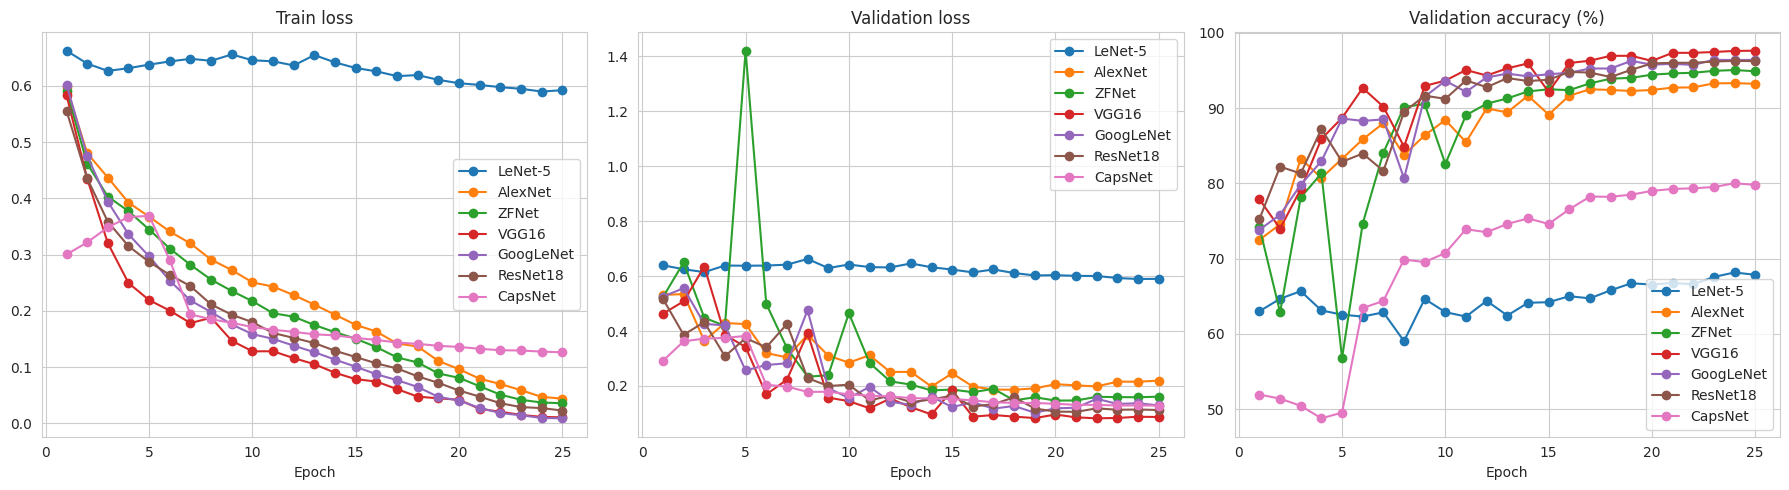

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, r in results.items():
    h, ep = r["history"], range(1, len(r["history"]["val_acc"]) + 1)
    axes[0].plot(ep, h["train_loss"], marker="o", label=name)
    axes[1].plot(ep, h["val_loss"], marker="o", label=name)
    axes[2].plot(ep, [a * 100 for a in h["val_acc"]], marker="o", label=name)
for ax, t in zip(axes, ["Train loss", "Validation loss", "Validation accuracy (%)"]):
    ax.set_title(t); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "kurva_training.png"), dpi=150); plt.show()

### 7.3 Perbandingan metrik, ukuran, dan kecepatan
Akurasi tertinggi **bukan satu-satunya** kriteria: model yang akurat tapi 60× lebih besar dan 5× lebih lambat belum tentu pilihan terbaik.

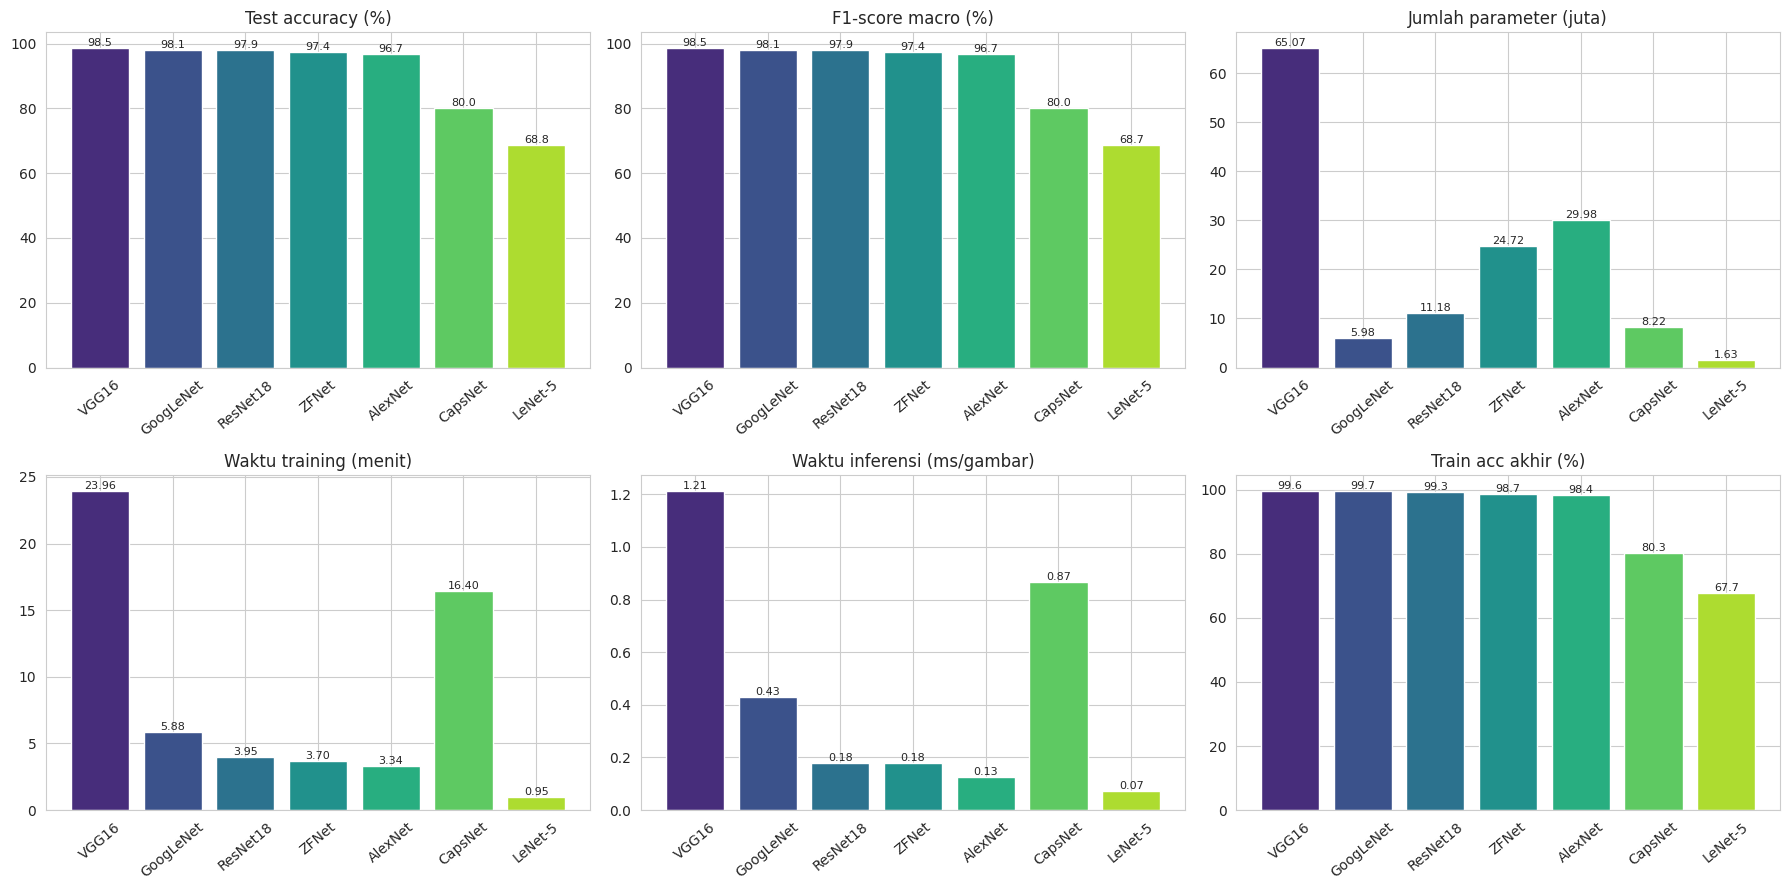

In [17]:
order = table["Model"].tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
panels = [("Test_Acc", "Test accuracy (%)", 100), ("F1", "F1-score macro (%)", 100),
          ("Params_M", "Jumlah parameter (juta)", 1), ("Train_Time_min", "Waktu training (menit)", 1),
          ("Infer_ms_per_img", "Waktu inferensi (ms/gambar)", 1), ("Final_Train_Acc", "Train acc akhir (%)", 100)]
for ax, (col, title, mult) in zip(axes.ravel(), panels):
    vals = [summary.set_index("Model").loc[m, col] * mult for m in order]
    bars = ax.bar(order, vals, color=sns.color_palette("viridis", len(order)))
    ax.set_title(title); ax.tick_params(axis="x", rotation=40)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.1f}" if mult == 100 else f"{v:.2f}",
                ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "perbandingan_metrik.png"), dpi=150); plt.show()

### 7.4 Confusion matrix (data test)
Baris = label sebenarnya, kolom = prediksi. Angka di luar diagonal adalah kesalahan.

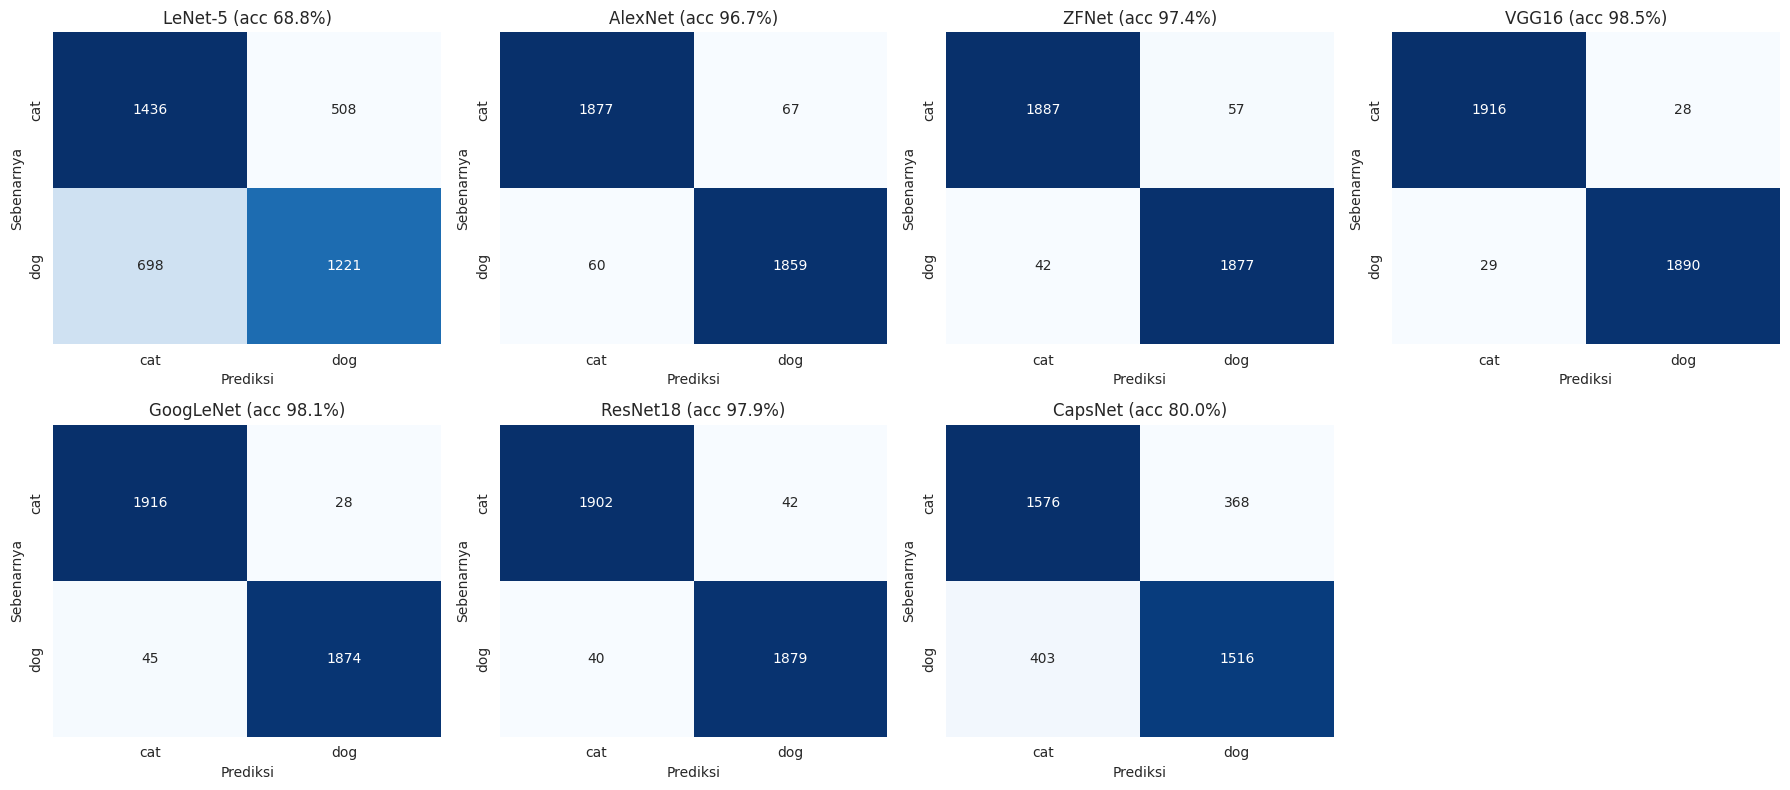

In [18]:
y_true = y_test.cpu().numpy()
n = len(results); cols = min(4, n); rows = math.ceil(n / cols)
fig, axes = plt.subplots(rows, cols, figsize=(4.5 * cols, 4 * rows))
axes = np.atleast_1d(axes).ravel()
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y_true, r["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{name} (acc {r['Test_Acc'] * 100:.1f}%)"); ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
for ax in axes[n:]: ax.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(WORK_DIR, "confusion_matrices.png"), dpi=150); plt.show()

### 7.5 Classification report model terbaik & contoh kesalahan

Model terbaik: VGG16

              precision    recall  f1-score   support

         cat     0.9851    0.9856    0.9853      1944
         dog     0.9854    0.9849    0.9851      1919

    accuracy                         0.9852      3863
   macro avg     0.9852    0.9852    0.9852      3863
weighted avg     0.9852    0.9852    0.9852      3863

Jumlah salah prediksi: 57 dari 3863


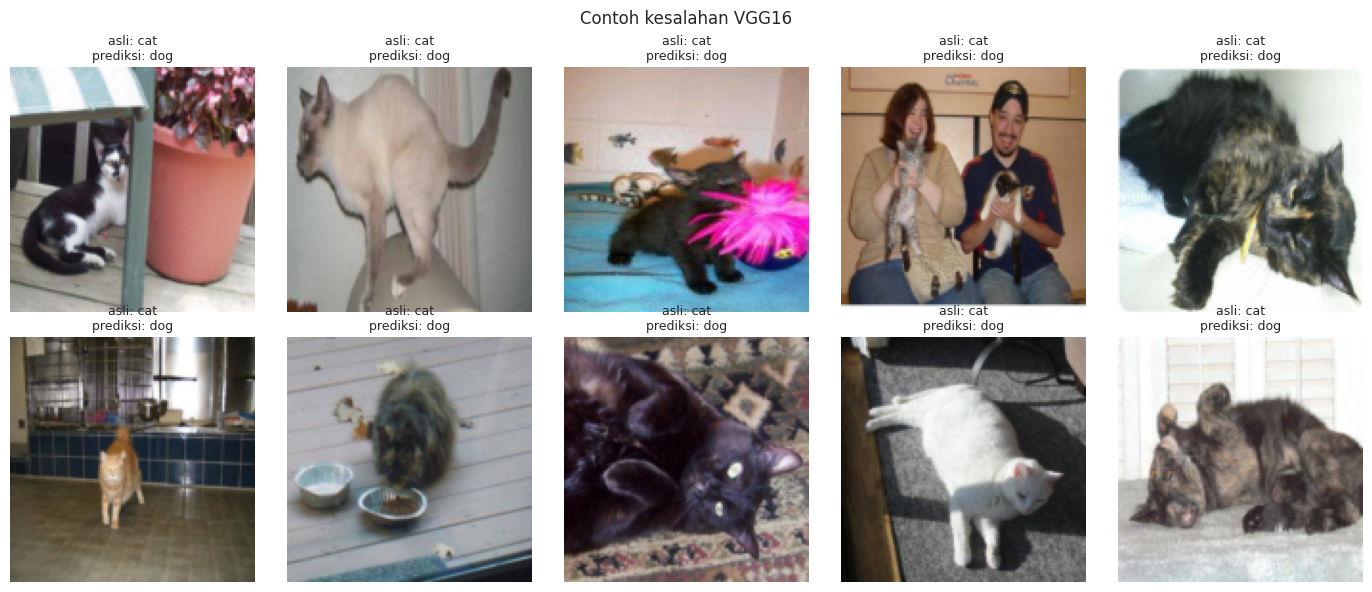

In [19]:
best_name = table.iloc[0]["Model"]
print(f"Model terbaik: {best_name}\n")
print(classification_report(y_true, results[best_name]["y_pred"], target_names=CLASS_NAMES, digits=4))

wrong = np.where(results[best_name]["y_pred"] != y_true)[0]
print(f"Jumlah salah prediksi: {len(wrong)} dari {len(y_true)}")
if len(wrong) > 0:
    show = wrong[:10]
    fig, axes = plt.subplots(2, 5, figsize=(14, 6))
    for ax, i in zip(axes.ravel(), show):
        ax.imshow(X_test[i].permute(1, 2, 0).cpu().numpy())
        ax.set_title(f"asli: {CLASS_NAMES[y_true[i]]}\nprediksi: {CLASS_NAMES[results[best_name]['y_pred'][i]]}", fontsize=9)
        ax.axis("off")
    for ax in axes.ravel()[len(show):]: ax.axis("off")
    plt.suptitle(f"Contoh kesalahan {best_name}"); plt.tight_layout(); plt.show()

## 8. Kesimpulan & Panduan Presentasi

> **Isi bagian ini dengan angka dari tabel di 7.1 setelah training selesai.**

### Kerangka kesimpulan
1. **Model terbaik** berdasarkan test accuracy: `____` (acc `__%`, F1 `__%`).
2. **Trade-off akurasi vs efisiensi:** bandingkan parameter, waktu training, dan waktu inferensi. Apakah model yang lebih besar sepadan dengan kenaikan akurasinya?
3. **Tren sejarah:** apakah urutan akurasi sejalan dengan urutan tahun (LeNet < AlexNet < ZFNet < VGG < GoogLeNet < ResNet)? Kalau ada yang menyimpang, jelaskan kenapa.
4. **Overfitting:** lihat `Final_Train_Acc` vs `Test_Acc`. Selisih besar = model menghafal data train (biasanya model dengan FC raksasa seperti AlexNet/ZFNet/VGG).
5. **CapsNet:** apakah kompetitif? Jelaskan keterbatasan routing dan training dari nol pada gambar natural.
6. **Keterbatasan:** hanya 1 run (satu seed), resolusi 128×128, ±12 epoch, tanpa pretrained weights, tanpa tuning hyperparameter per model. Hasil bisa berubah dengan setting lain.

### Kemungkinan pertanyaan dosen
- **Kenapa semua pakai input 128×128?** Supaya adil dan cukup cepat di Kaggle; semua model dibandingkan pada kondisi yang sama.
- **Kenapa tidak pakai pretrained?** Tujuannya membandingkan *arsitektur*. Pretrained menguji kualitas bobot ImageNet, bukan desain arsitektur.
- **Kenapa model dipilih dari validation, bukan test?** Mencegah data leakage; test hanya dipakai sekali untuk skor jujur.
- **Kenapa ada BatchNorm di AlexNet/ZFNet/VGG padahal aslinya tidak?** Training dari nol dalam waktu singkat butuh BN untuk stabil (menggantikan LRN pada AlexNet/ZFNet).
- **Kenapa ResNet-18, bukan ResNet-152?** Efisiensi waktu; konsep skip connection sama.
- **Kenapa CapsNet pakai margin loss?** Karena outputnya vektor; panjang vektor dipaksa >0.9 untuk kelas benar dan <0.1 untuk kelas salah.

### Pengembangan lanjutan (opsional)
- Transfer learning (pretrained ImageNet) untuk VGG/ResNet/GoogLeNet → bandingkan dengan from scratch
- Ulangi dengan beberapa seed dan laporkan rata-rata ± standar deviasi
- ResNet-50, Grad-CAM untuk melihat bagian gambar yang diperhatikan model